# Sharp Image Recovery with a GAN (128x128 colour flower photos)
Runtime > Change runtime type > **T4 GPU**, then Runtime > Run all.

Why this is sharper than the CIFAR-10 version:
1. **Higher resolution** photos (128x128 instead of 32x32), so there is real detail to recover.
2. **PatchGAN discriminator** that looks at local texture and sees the damaged image as context.
3. **Weaker L1 weight**, so the adversarial loss can create crisp texture instead of a blurry average.

In [ ]:
import time, torch, torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

IMG = 128          # image size
HOLE = 48          # missing square size (pixels)
BATCH_SIZE = 32
EPOCHS = 60
LR = 2e-4
L1_WEIGHT = 20     # lower = sharper but riskier, higher = safer but blurrier

Using device: cuda


## 1. Data: Oxford Flowers-102 (colourful photos), cached in memory as 128x128

100%|██████████| 345M/345M [00:13<00:00, 26.0MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.74MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 17.6MB/s]


Train: (7169, 3, 128, 128)  Val: (1020, 3, 128, 128)  (53s)


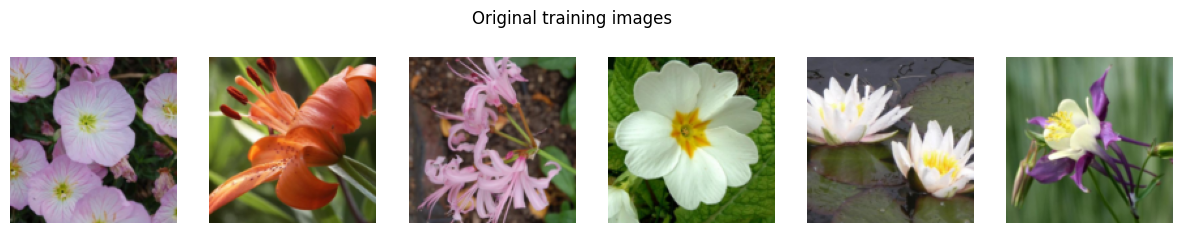

In [ ]:
tfm = transforms.Compose([
    transforms.Resize(IMG),
    transforms.CenterCrop(IMG),
    transforms.PILToTensor(),          # uint8 tensor (3,H,W) - small in memory
])

def load_split(split):
    ds = datasets.Flowers102("./data", split=split, download=True, transform=tfm)
    loader = DataLoader(ds, batch_size=256, shuffle=False, num_workers=2)
    return torch.cat([x for x, _ in loader])

t0 = time.time()
train_u8 = torch.cat([load_split("train"), load_split("test")])   # ~7,100 images for training
val_u8   = load_split("val")                                      # ~1,000 unseen images for testing
print("Train:", tuple(train_u8.shape), " Val:", tuple(val_u8.shape), f" ({time.time()-t0:.0f}s)")

train_u8 = train_u8.to(device); val_u8 = val_u8.to(device)

def prep(u8):                 # uint8 [0,255] -> float [-1,1]
    return u8.float() / 127.5 - 1.0

def to_img(t):                # tensor [-1,1] (C,H,W) -> numpy [0,1]
    return ((t.detach().cpu().clamp(-1, 1) + 1) / 2).permute(1, 2, 0).numpy()

def random_mask(b, hole=HOLE):
    # (b,1,IMG,IMG), 1 where pixels are MISSING; random square position per image
    ys = torch.randint(0, IMG - hole + 1, (b,), device=device)
    xs = torch.randint(0, IMG - hole + 1, (b,), device=device)
    idx = torch.arange(IMG, device=device)
    in_y = (idx[None, :, None] >= ys[:, None, None]) & (idx[None, :, None] < (ys + hole)[:, None, None])
    in_x = (idx[None, None, :] >= xs[:, None, None]) & (idx[None, None, :] < (xs + hole)[:, None, None])
    return (in_y & in_x).float().unsqueeze(1)

fig, ax = plt.subplots(1, 6, figsize=(15, 2.7))
for i in range(6):
    ax[i].imshow(to_img(prep(train_u8[i * (len(train_u8) // 6)]))); ax[i].axis("off")
plt.suptitle("Original training images"); plt.show()

## 2. Models





In [ ]:
def down(i, o, bn=True):
    layers = [nn.Conv2d(i, o, 4, 2, 1, bias=not bn)]
    if bn: layers.append(nn.BatchNorm2d(o))
    layers.append(nn.LeakyReLU(0.2, inplace=True))
    return nn.Sequential(*layers)

def up(i, o):
    return nn.Sequential(nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))

class Generator(nn.Module):
    # U-Net: input = damaged RGB + mask (4 channels). Skip connections keep fine detail.
    def __init__(self):
        super().__init__()
        self.e1 = down(4, 64, bn=False)   # 128 -> 64
        self.e2 = down(64, 128)           # 64 -> 32
        self.e3 = down(128, 256)          # 32 -> 16
        self.e4 = down(256, 512)          # 16 -> 8
        self.e5 = down(512, 512)          # 8 -> 4
        self.e6 = down(512, 512)          # 4 -> 2
        self.d6 = up(512, 512)            # 2 -> 4
        self.d5 = up(1024, 512)           # 4 -> 8
        self.d4 = up(1024, 256)           # 8 -> 16
        self.d3 = up(512, 128)            # 16 -> 32
        self.d2 = up(256, 64)             # 32 -> 64
        self.d1 = nn.Sequential(nn.ConvTranspose2d(128, 3, 4, 2, 1), nn.Tanh())  # 64 -> 128

    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(e1); e3 = self.e3(e2)
        e4 = self.e4(e3); e5 = self.e5(e4); e6 = self.e6(e5)
        d6 = self.d6(e6)
        d5 = self.d5(torch.cat([d6, e5], 1))
        d4 = self.d4(torch.cat([d5, e4], 1))
        d3 = self.d3(torch.cat([d4, e3], 1))
        d2 = self.d2(torch.cat([d3, e2], 1))
        return self.d1(torch.cat([d2, e1], 1))

class Discriminator(nn.Module):
    # Conditional PatchGAN: sees (damaged image + mask + candidate image) and scores local patches
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(7, 64, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),                                         # 64
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),      # 32
            nn.Conv2d(128, 256, 4, 2, 1, bias=False), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),     # 16
            nn.Conv2d(256, 512, 4, 1, 1, bias=False), nn.BatchNorm2d(512), nn.LeakyReLU(0.2, inplace=True),     # 15
            nn.Conv2d(512, 1, 4, 1, 1),                                                                         # 14x14 patch scores
        )
    def forward(self, damaged, mask, candidate):
        return self.net(torch.cat([damaged, mask, candidate], 1))

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

G = Generator().to(device); D = Discriminator().to(device)
G.apply(init_weights); D.apply(init_weights)

bce = nn.BCEWithLogitsLoss()
opt_G = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))

def recover(img, mask):
    damaged = img * (1 - mask)
    out = G(torch.cat([damaged, mask], 1))
    recovered = out * mask + img * (1 - mask)      # prediction is pasted ONLY into the hole
    return damaged, out, recovered

fixed_img = prep(val_u8[:6]); fixed_mask = random_mask(6)

def show_progress(title):
    G.eval()
    with torch.no_grad():
        damaged, _, rec = recover(fixed_img, fixed_mask)
    G.train()
    fig, ax = plt.subplots(3, 6, figsize=(15, 8))
    for i in range(6):
        for r, (im, name) in enumerate([(damaged, "Damaged"), (rec, "Recovered"), (fixed_img, "Original")]):
            ax[r, i].imshow(to_img(im[i])); ax[r, i].axis("off")
            if i == 0: ax[r, i].set_title(name, loc="left", fontsize=11)
    plt.suptitle(title); plt.tight_layout(); plt.show()

## 3. Training

In [ ]:
g_losses, d_losses = [], []
n = train_u8.size(0)

for epoch in range(1, EPOCHS + 1):
    t0 = time.time(); g_run = d_run = 0.0
    perm = torch.randperm(n, device=device)
    steps = n // BATCH_SIZE

    for s in range(steps):
        img = prep(train_u8[perm[s * BATCH_SIZE:(s + 1) * BATCH_SIZE]])
        if torch.rand(1).item() < 0.5:
            img = torch.flip(img, dims=[3])            # random horizontal flip (augmentation)
        b = img.size(0)
        mask = random_mask(b)
        damaged, out, recovered = recover(img, mask)

        # ---- Discriminator ----
        real_pred = D(damaged, mask, img)
        fake_pred = D(damaged, mask, recovered.detach())
        loss_D = (bce(real_pred, torch.full_like(real_pred, 0.9)) +      # label smoothing
                  bce(fake_pred, torch.zeros_like(fake_pred))) / 2
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()

        # ---- Generator ----
        fake_pred = D(damaged, mask, recovered)
        adv = bce(fake_pred, torch.ones_like(fake_pred))
        l1 = (torch.abs(out - img) * mask).sum() / (mask.sum() * 3 + 1e-8)
        loss_G = adv + L1_WEIGHT * l1
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()

        g_run += loss_G.item(); d_run += loss_D.item()

    g_losses.append(g_run / steps); d_losses.append(d_run / steps)
    print(f"Epoch [{epoch}/{EPOCHS}]  D: {d_losses[-1]:.3f}  G: {g_losses[-1]:.3f}  ({time.time()-t0:.0f}s)")
    if epoch in (1, 10, 30) or epoch == EPOCHS:
        show_progress(f"Image recovery - epoch {epoch}")

## 4. Prediction: ONE image that shows the result (Damaged -> Recovered -> Original)

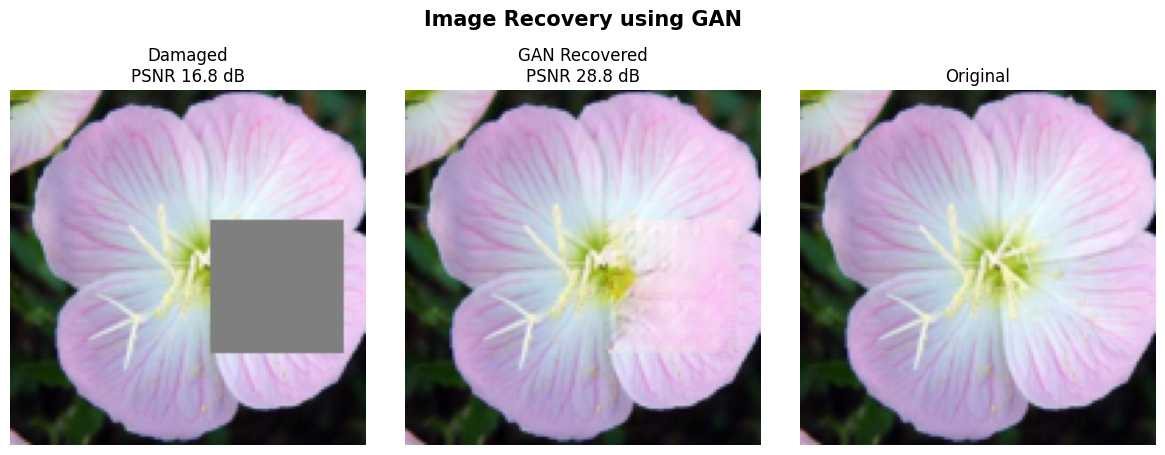

Saved: recovery_result.png


In [ ]:
def psnr(a, b):  # a, b in [-1,1]; higher = closer to the original
    mse = ((a - b) / 2).pow(2).flatten(1).mean(1)
    return 10 * torch.log10(1.0 / (mse + 1e-10))

def predict_one(index=0, save_path="recovery_result.png"):
    G.eval()
    img = prep(val_u8[index:index + 1])
    mask = random_mask(1)
    with torch.no_grad():
        damaged, _, rec = recover(img, mask)
    p_dam, p_rec = psnr(damaged, img).item(), psnr(rec, img).item()

    fig, ax = plt.subplots(1, 3, figsize=(12, 4.6))
    for a, im, t in zip(ax, [damaged, rec, img],
                        [f"Damaged\nPSNR {p_dam:.1f} dB", f"GAN Recovered\nPSNR {p_rec:.1f} dB", "Original"]):
        a.imshow(to_img(im[0])); a.set_title(t, fontsize=12); a.axis("off")
    fig.suptitle("Image Recovery using GAN", fontsize=15, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.92])
    fig.savefig(save_path, dpi=200, bbox_inches="tight"); plt.show()
    print("Saved:", save_path)

predict_one(index=5)    # change the number (0 to ~1000) to try other unseen images

Average PSNR  damaged: 19.63 dB   ->   recovered: 23.49 dB


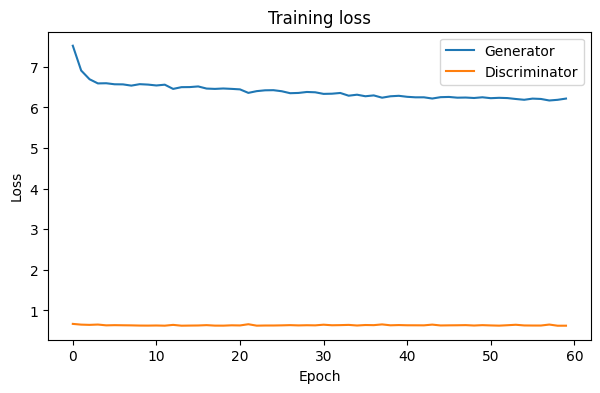

Saved recovery_generator.pth


In [ ]:
# Average quality on unseen validation images (higher PSNR = better recovery)
G.eval(); dam_psnr, rec_psnr = [], []
with torch.no_grad():
    for i in range(0, val_u8.size(0) - 99, 100):
        img = prep(val_u8[i:i + 100]); mask = random_mask(img.size(0))
        damaged, _, rec = recover(img, mask)
        dam_psnr.append(psnr(damaged, img).mean().item()); rec_psnr.append(psnr(rec, img).mean().item())
print(f"Average PSNR  damaged: {sum(dam_psnr)/len(dam_psnr):.2f} dB   ->   recovered: {sum(rec_psnr)/len(rec_psnr):.2f} dB")

plt.figure(figsize=(7, 4))
plt.plot(g_losses, label="Generator"); plt.plot(d_losses, label="Discriminator")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Training loss"); plt.show()

torch.save(G.state_dict(), "recovery_generator.pth")
print("Saved recovery_generator.pth")

## 5. Test with YOUR OWN image (interactive)
Run the next two cells. Upload any photo, choose where the hole goes, and the GAN recovers it.
It works best on **flower photos** (that is what it was trained on). Other photos may recover less accurately.

In [ ]:
import numpy as np
from PIL import Image

def recover_user_image(path, x=None, y=None, save_path="my_recovery_result.png"):
    # 1) load + centre-crop to a square + resize to 128x128
    im = Image.open(path).convert("RGB")
    w, h = im.size; s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    im = im.crop((left, top, left + s, top + s)).resize((IMG, IMG), Image.LANCZOS)
    img = torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(127.5).sub(1).unsqueeze(0).to(device)

    # 2) place the hole (x, y = top-left corner). Random if not given.
    lim = IMG - HOLE
    x = int(torch.randint(0, lim + 1, (1,))) if x is None else max(0, min(lim, int(x)))
    y = int(torch.randint(0, lim + 1, (1,))) if y is None else max(0, min(lim, int(y)))
    mask = torch.zeros(1, 1, IMG, IMG, device=device)
    mask[:, :, y:y + HOLE, x:x + HOLE] = 1

    # 3) recover
    G.eval()
    with torch.no_grad():
        damaged, _, rec = recover(img, mask)
    p_dam, p_rec = psnr(damaged, img).item(), psnr(rec, img).item()

    fig, ax = plt.subplots(1, 3, figsize=(12, 4.6))
    for a, t_img, t in zip(ax, [damaged, rec, img],
                           [f"Damaged (hole at x={x}, y={y})\nPSNR {p_dam:.1f} dB",
                            f"GAN Recovered\nPSNR {p_rec:.1f} dB", "Original"]):
        a.imshow(to_img(t_img[0])); a.set_title(t, fontsize=12); a.axis("off")
    fig.suptitle("Image Recovery using GAN", fontsize=15, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.92])
    fig.savefig(save_path, dpi=200, bbox_inches="tight"); plt.show()
    print("Saved:", save_path)

Saving outside_flower.jpg to outside_flower.jpg
Hole position as x,y (each 0-80), or press Enter for random: 


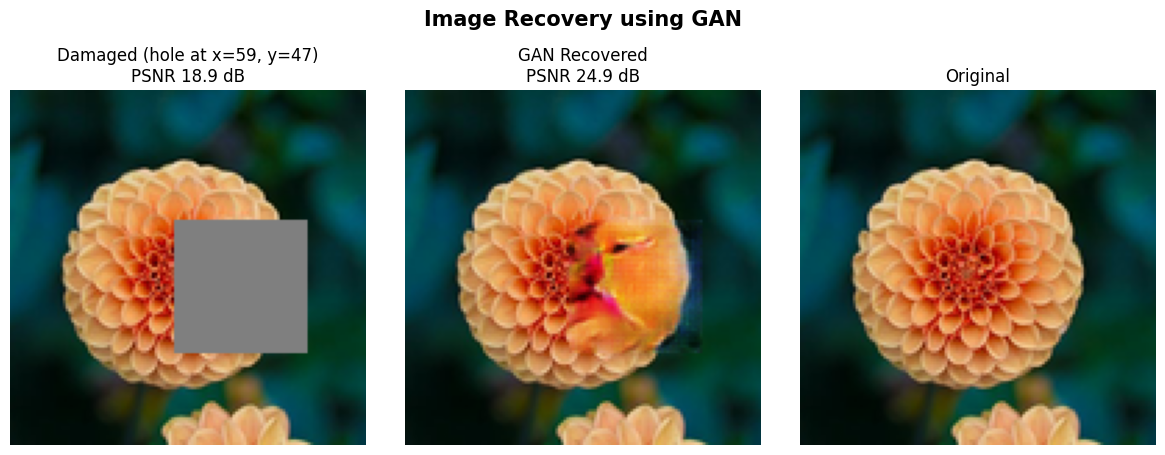

Saved: my_recovery_result.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Run this cell again any time to try another image
from google.colab import files

uploaded = files.upload()                 # choose an image file from your computer
path = next(iter(uploaded))

txt = input(f"Hole position as x,y (each 0-{IMG - HOLE}), or press Enter for random: ").strip()
if txt:
    x, y = [int(v) for v in txt.replace(" ", "").split(",")]
else:
    x = y = None

recover_user_image(path, x, y)

try:
    files.download("my_recovery_result.png")   # downloads the result image to your computer
except Exception as e:
    print("Download skipped:", e)

## 6. Website interface (Gradio)
Run the next two cells. You will get a **public link** (https://xxxx.gradio.live) plus the app shown right inside Colab.
Upload a photo, move the sliders to place the hole, press **Recover image**. Keep this cell running while you use the site.

In [ ]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
import gradio as gr
print("Gradio version:", gr.__version__)

In [ ]:
SHOW = 384   # size of images displayed on the website

def _square128(pil_img):
    im = pil_img.convert("RGB"); w, h = im.size; s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return im.crop((left, top, left + s, top + s)).resize((IMG, IMG), Image.LANCZOS)

def _build(pil_img, x, y):
    im = _square128(pil_img)
    img = torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(127.5).sub(1).unsqueeze(0).to(device)
    lim = IMG - HOLE
    x = max(0, min(lim, int(x))); y = max(0, min(lim, int(y)))
    mask = torch.zeros(1, 1, IMG, IMG, device=device)
    mask[:, :, y:y + HOLE, x:x + HOLE] = 1
    return img, mask, x, y

def _to_pil(t):
    arr = (to_img(t[0]) * 255).round().astype("uint8")
    return Image.fromarray(arr).resize((SHOW, SHOW), Image.BICUBIC)

def ui_preview(pil_img, x, y):
    if pil_img is None:
        return None
    img, mask, x, y = _build(pil_img, x, y)
    return _to_pil(img * (1 - mask))

def ui_recover(pil_img, x, y):
    if pil_img is None:
        raise gr.Error("Please upload an image first.")
    img, mask, x, y = _build(pil_img, x, y)
    G.eval()
    with torch.no_grad():
        damaged, _, rec = recover(img, mask)
    p_dam, p_rec = psnr(damaged, img).item(), psnr(rec, img).item()
    info = (f"**Hole at x={x}, y={y}**   |   Damaged PSNR: **{p_dam:.1f} dB**   ->   "
            f"Recovered PSNR: **{p_rec:.1f} dB**  (higher is better)")
    return _to_pil(damaged), _to_pil(rec), _to_pil(img), info

def random_xy():
    lim = IMG - HOLE
    return int(torch.randint(0, lim + 1, (1,))), int(torch.randint(0, lim + 1, (1,)))

with gr.Blocks(title="GAN Image Recovery") as demo:
    gr.Markdown("# GAN Image Recovery\nUpload a photo, choose where the hole goes, and the GAN will fill it back in. "
                "Works best on flower photos (what it was trained on).")
    with gr.Row():
        with gr.Column():
            inp = gr.Image(type="pil", label="1. Upload a photo")
            x_s = gr.Slider(0, IMG - HOLE, value=40, step=1, label="2. Hole position - X (left to right)")
            y_s = gr.Slider(0, IMG - HOLE, value=40, step=1, label="   Hole position - Y (top to bottom)")
            rand_btn = gr.Button("Random position")
            run_btn = gr.Button("3. Recover image", variant="primary")
        with gr.Column():
            out_dmg = gr.Image(type="pil", label="Damaged", interactive=False)
            out_rec = gr.Image(type="pil", label="GAN Recovered", interactive=False)
            out_org = gr.Image(type="pil", label="Original (128x128)", interactive=False)
            out_info = gr.Markdown()

    inp.change(ui_preview, [inp, x_s, y_s], out_dmg)       # live preview of the hole
    x_s.change(ui_preview, [inp, x_s, y_s], out_dmg)
    y_s.change(ui_preview, [inp, x_s, y_s], out_dmg)
    rand_btn.click(random_xy, None, [x_s, y_s])
    run_btn.click(ui_recover, [inp, x_s, y_s], [out_dmg, out_rec, out_org, out_info])

demo.launch(share=True, debug=True)   # opens the website; keep this cell running

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://b3b55cfea75ef94141.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://b3b55cfea75ef94141.gradio.live
